# Complete Hybrid Mammography Classification Pipeline (Fixed)
## Swin-T + ResNet-50 + EfficientNet-B7/B2 | CBIS-DDSM | Kaggle GPU

> **Fixes applied vs. original notebook**
> 1. **Cell 2 no longer stalls**: filesystem index built once; `rglob` removed from per-row loop.
> 2. **Patient-level split CSVs created automatically** in Cell 2 (no missing-file crash in Cell 3).
> 3. **Preprocessing is no longer destructive**: `USE_THRESHOLD_ROI=False` (threshold 193 zeroed 99% of breast tissue).
> 4. **Caching is fast**: images resized *before* filters; NLM is OFF by default — cuts cache time from ~7 h to ~2 min.
> 5. **Memory safety**: EfficientNet-B7 can be swapped to B2 via `EFFNET_VARIANT` flag if CUDA OOM occurs.

**Run cells in order 1 → 9.**
- First run builds image cache (~2 min). Subsequent runs reuse it.
- If Kaggle session restarts, re-run from Cell 1; `/kaggle/working` is ephemeral.


In [1]:
# CELL 1 — Imports, configuration, GPU diagnostics
import os, time, copy, random, gc, json
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image

import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    swin_t, Swin_T_Weights,
    resnet50, ResNet50_Weights,
    efficientnet_b2, EfficientNet_B2_Weights,
    efficientnet_b7, EfficientNet_B7_Weights,
)
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, precision_score,
    recall_score, confusion_matrix, classification_report,
)
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_ROOT  = Path("/kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset")
PREP_DIR   = "/kaggle/working/cbis_ddsm_preparation"
TRAIN_CSV  = os.path.join(PREP_DIR, "cbis_full_train.csv")
VAL_CSV    = os.path.join(PREP_DIR, "cbis_full_validation.csv")
TEST_CSV   = os.path.join(PREP_DIR, "cbis_full_test.csv")
CACHE_ROOT = "/kaggle/working/cbis_preprocessed_cache"
OUT_DIR    = PREP_DIR
os.makedirs(CACHE_ROOT, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# ── Training hyper-parameters ──────────────────────────────────────────────────
IMG_SIZE        = 256
BATCH_SIZE      = 2
EVAL_BATCH_SIZE = 2
NUM_WORKERS     = 2
HEAD_EPOCHS     = 2
FINETUNE_EPOCHS = 12
PATIENCE        = 4

# ── EfficientNet variant: "b2" (default, safe) or "b7" (heavy, may OOM on T4) ─
EFFNET_VARIANT = "b2"   # change to "b7" only if you have >=24 GB VRAM

# ── Preprocessing toggles ──────────────────────────────────────────────────────
# FIX 3 & 4: Threshold ROI off (was destroying 99% of breast tissue).
#             NLM off by default (saves ~6 h of caching time on full-res images).
#             Resize happens BEFORE any filter (massive speed gain).
USE_THRESHOLD_ROI = False   # set True only after controlled validation-set testing
THRESHOLD_VALUE   = 193     # only used when USE_THRESHOLD_ROI is True
USE_NLM_DENOISING = False   # very slow on full-res; bilinear resize already smooths
USE_MEDIAN_FILTER = False
USE_CLAHE         = True    # beneficial for mammograms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 65)
print("DEVICE:", device)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
    torch.cuda.reset_peak_memory_stats()
    x = torch.randn(512, 512, device=device)
    torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(5):
        x = x @ x
    torch.cuda.synchronize()
    print("GPU compute test: PASS in", round(time.time()-t0, 3), "seconds")
    print("Allocated memory:", round(torch.cuda.memory_allocated()/1024**3, 2), "GiB")
print("EfficientNet variant:", EFFNET_VARIANT)
print("Cache directory:", CACHE_ROOT)


DEVICE: cuda
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU count: 2
GPU compute test: PASS in 0.145 seconds
Allocated memory: 0.01 GiB
EfficientNet variant: b2
Cache directory: /kaggle/working/cbis_preprocessed_cache


In [2]:
# CELL 2 — Build CBIS-DDSM manifest AND create patient-level split CSVs
# KEY FIX: Build series-UID-to-JPEG index from the ACTUAL folder structure.
# In the awsaf49 Kaggle dataset, JPEGs are stored as:
#   DATA_ROOT/jpeg/SERIES_UID/1-001.jpg
# So the folder name IS the series UID — no dicom_info.csv lookup needed.
import re
from collections import defaultdict

CSV_DIR   = DATA_ROOT / 'csv'
DICOM_CSV = CSV_DIR / 'dicom_info.csv'
CASE_CSVS = [
    CSV_DIR / 'mass_case_description_train_set.csv',
    CSV_DIR / 'mass_case_description_test_set.csv',
    CSV_DIR / 'calc_case_description_train_set.csv',
    CSV_DIR / 'calc_case_description_test_set.csv',
]

for p in [DICOM_CSV, *CASE_CSVS]:
    if not p.exists():
        raise FileNotFoundError(f'Required file not found: {p}')

# STEP 1: Build series_uid -> [jpeg_paths] from folder structure
# In CBIS-DDSM the parent folder of each JPEG IS the SeriesInstanceUID.
# This avoids the duplicate-filename problem in the naive file scan.
print('Building series-UID index from JPEG folder structure...')
t0 = time.time()
series_to_jpegs = defaultdict(list)
uid_pat = re.compile(r'^1\.(?:\d+\.)+\d+$')

jpeg_root = DATA_ROOT / 'jpeg'
if jpeg_root.exists():
    for series_dir in jpeg_root.iterdir():
        if series_dir.is_dir() and uid_pat.match(series_dir.name):
            for f in series_dir.iterdir():
                if f.is_file() and f.suffix.lower() in {'.jpg', '.jpeg'}:
                    series_to_jpegs[series_dir.name].append(str(f.resolve()))
else:
    print('WARNING: jpeg/ subfolder not found. Falling back to full rglob scan.')
    for f in DATA_ROOT.rglob('*.jpg'):
        parent = f.parent.name
        if uid_pat.match(parent):
            series_to_jpegs[parent].append(str(f.resolve()))

total_jpegs = sum(len(v) for v in series_to_jpegs.values())
print(f'  Unique series UIDs: {len(series_to_jpegs)}')
print(f'  Total JPEG files  : {total_jpegs}')
print(f'  Index built in    : {time.time()-t0:.1f}s')

# Show a few examples so we can verify the index is correct
print('\nSample entries:')
for uid, paths in list(series_to_jpegs.items())[:3]:
    print(f'  {uid[:55]}... -> {len(paths)} file(s), e.g. {Path(paths[0]).name}')

# STEP 2: Resolve a series UID to a single JPEG
def resolve_series_to_jpeg(series_uid):
    candidates = series_to_jpegs.get(series_uid, [])
    if len(candidates) == 1:
        return candidates[0], 'exact'
    if len(candidates) > 1:
        # Prefer images that are not ROI or mask crops
        full_imgs = [p for p in candidates
                     if 'mask' not in Path(p).name.lower()
                     and 'roi'  not in Path(p).name.lower()]
        if len(full_imgs) == 1:
            return full_imgs[0], 'filtered'
        return None, f'ambiguous({len(candidates)})'
    return None, 'not_found'

# STEP 3: Extract all UID-like tokens from a case CSV path
def extract_uids(value):
    if pd.isna(value):
        return []
    return re.findall(r'1(?:\.\d+)+', str(value))

# STEP 4: Read case CSVs
case_frames = []
for csv_path in CASE_CSVS:
    df = pd.read_csv(csv_path, low_memory=False)
    df['source_csv'] = csv_path.name
    case_frames.append(df)
cases = pd.concat(case_frames, ignore_index=True)

for col in ('patient_id', 'pathology', 'image file path'):
    if col not in cases.columns:
        raise ValueError(f"Case CSVs missing required column: '{col}'")

# Diagnostics: show what the case CSV paths look like
print('\nSample case CSV image file paths and their extracted UIDs:')
for v in cases['image file path'].dropna().head(4):
    uids = extract_uids(v)
    hits = [u for u in uids if u in series_to_jpegs]
    print(f'  path : {str(v)[:80]}')
    print(f'  UIDs : {len(uids)} found, {len(hits)} match series_to_jpegs')

# STEP 5: Build manifest rows
# Try EVERY UID in the path until one resolves to a JPEG.
manifest_rows = []
reason_counts = defaultdict(int)

for row_index, row in cases.iterrows():
    case_path = row.get('image file path')
    uids = extract_uids(case_path)

    matched_path = None
    for uid in uids:
        path, status = resolve_series_to_jpeg(uid)
        if path is not None:
            matched_path = path
            matched_uid  = uid
            break

    if matched_path is None:
        reason_counts[f'no_uid_matched({len(uids)}_uids)'] += 1
        continue

    pathology = str(row.get('pathology', '')).strip().upper()
    if 'MALIGNANT' in pathology:
        binary_label = 1
    elif 'BENIGN' in pathology:
        binary_label = 0
    else:
        reason_counts[f'unknown_pathology:{pathology}'] += 1
        continue

    manifest_rows.append({
        'patient_id':    str(row.get('patient_id', '')).strip(),
        'pathology':     pathology,
        'binary_label':  binary_label,
        'image_path':    matched_path,
        'resolved_path': matched_path,
        'series_uid':    matched_uid,
        'source_csv':    row.get('source_csv'),
    })

manifest = pd.DataFrame(manifest_rows)

# STEP 6: Summary
print('\n' + '='*60)
print(f'Case CSV rows            : {len(cases)}')
print(f'Successfully mapped rows : {len(manifest_rows)}')
if reason_counts:
    print('Failure reasons:')
    for reason, count in sorted(reason_counts.items(), key=lambda x: -x[1]):
        print(f'  {count:5d}  {reason}')

# STEP 7: Deduplication / conflict removal
if not manifest.empty:
    lc = manifest.groupby('image_path')['binary_label'].nunique()
    bad = lc[lc > 1].index
    if len(bad):
        print(f'Removing {len(bad)} paths with conflicting labels')
        manifest = manifest[~manifest['image_path'].isin(bad)].copy()
    pc = manifest.groupby('image_path')['patient_id'].nunique()
    bad = pc[pc > 1].index
    if len(bad):
        print(f'Removing {len(bad)} paths linked to multiple patient IDs')
        manifest = manifest[~manifest['image_path'].isin(bad)].copy()
    manifest = manifest.drop_duplicates(
        subset=['image_path', 'patient_id', 'binary_label']
    ).reset_index(drop=True)

print(f'\nFinal manifest rows: {len(manifest)}')

if manifest.empty:
    print('\nDEBUG — case CSV UIDs vs series_to_jpegs:')
    for v in cases['image file path'].dropna().head(5):
        uids = extract_uids(v)
        print(f'  path: {v}')
        for u in uids:
            print(f'    UID={u[:60]}  in_index={u in series_to_jpegs}')
    raise RuntimeError(
        'Manifest is empty. Check the DEBUG output above.\n'
        'The UIDs from case CSVs do not match the jpeg/ folder names.'
    )

print('Label distribution:')
print(manifest['binary_label'].map({0: 'BENIGN', 1: 'MALIGNANT'}).value_counts())

# STEP 8: Patient-level train / val / test splits
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, temp_idx = next(gss1.split(manifest, groups=manifest['patient_id']))
train_df_raw = manifest.iloc[train_idx].copy()
temp_df_raw  = manifest.iloc[temp_idx].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
val_idx, test_idx = next(gss2.split(temp_df_raw, groups=temp_df_raw['patient_id']))
val_df_raw  = temp_df_raw.iloc[val_idx].copy()
test_df_raw = temp_df_raw.iloc[test_idx].copy()

tr_pat = set(train_df_raw.patient_id)
va_pat = set(val_df_raw.patient_id)
te_pat = set(test_df_raw.patient_id)
assert tr_pat.isdisjoint(va_pat), 'LEAK: train/val'
assert tr_pat.isdisjoint(te_pat), 'LEAK: train/test'
assert va_pat.isdisjoint(te_pat), 'LEAK: val/test'

os.makedirs(PREP_DIR, exist_ok=True)
train_df_raw.to_csv(TRAIN_CSV, index=False)
val_df_raw.to_csv(VAL_CSV, index=False)
test_df_raw.to_csv(TEST_CSV, index=False)

print(f'\nTrain: {len(train_df_raw)} | Val: {len(val_df_raw)} | Test: {len(test_df_raw)}')
print('Patient-level split: no leaks OK')
print(f'CSVs saved to: {PREP_DIR}')


Building series-UID index from JPEG folder structure...
  Unique series UIDs: 6774
  Total JPEG files  : 10237
  Index built in    : 207.1s

Sample entries:
  1.3.6.1.4.1.9590.100.1.2.100018879311824535125115145152... -> 2 file(s), e.g. 1-263.jpg
  1.3.6.1.4.1.9590.100.1.2.100131208110604806117271735422... -> 1 file(s), e.g. 1-126.jpg
  1.3.6.1.4.1.9590.100.1.2.100522099512256189513864912954... -> 1 file(s), e.g. 1-231.jpg

Sample case CSV image file paths and their extracted UIDs:
  path : Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.4221127222131896498076114
  UIDs : 2 found, 1 match series_to_jpegs
  path : Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.319478999311971442426185
  UIDs : 2 found, 1 match series_to_jpegs
  path : Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.3471078678126566287098643
  UIDs : 2 found, 1 match series_to_jpegs
  path : Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.272600286511817402806912
  UIDs : 2 found, 1 match s

In [3]:
# CELL 3 — Load manifests, validate files and patient splits
for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    if not os.path.isfile(p):
        raise FileNotFoundError(
            f"Missing split manifest: {p}\n"
            "Run Cell 2 first (it creates these files)."
        )

required_cols = {"resolved_path", "binary_label", "patient_id"}
label_map = {"benign": 0, "malignant": 1, "0": 0, "1": 1}

def prepare_manifest(path, split_name):
    df = pd.read_csv(path)
    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"{split_name} manifest missing columns: {missing}")
    df = df.copy()
    df["resolved_path"] = df["resolved_path"].astype(str).str.strip()
    df["patient_id"]    = df["patient_id"].astype(str).str.strip()
    raw_labels = df["binary_label"].astype(str).str.strip().str.lower()
    mapped = raw_labels.map(label_map)
    if mapped.isna().any():
        raise ValueError(
            f"{split_name} has unsupported labels: "
            f"{raw_labels[mapped.isna()].unique().tolist()}"
        )
    df["binary_label"] = mapped.astype(int)
    if df.empty:
        raise ValueError(f"{split_name} manifest is empty.")
    if df["binary_label"].nunique() != 2:
        raise ValueError(f"{split_name} must have both benign and malignant rows.")
    missing_files = [p for p in df["resolved_path"] if not os.path.isfile(p)]
    if missing_files:
        raise FileNotFoundError(
            f"{split_name}: {len(missing_files)} image paths missing.\n"
            f"Example: {missing_files[0]}"
        )
    print(
        f"{split_name:12s}: images={len(df):4d}, "
        f"patients={df.patient_id.nunique():4d}, "
        f"benign={(df.binary_label==0).sum():4d}, "
        f"malignant={(df.binary_label==1).sum():4d}"
    )
    return df.reset_index(drop=True)

train_df = prepare_manifest(TRAIN_CSV, "Train")
val_df   = prepare_manifest(VAL_CSV,   "Validation")
test_df  = prepare_manifest(TEST_CSV,  "Test")

tr_p = set(train_df.patient_id)
va_p = set(val_df.patient_id)
te_p = set(test_df.patient_id)
assert tr_p.isdisjoint(va_p), "Patient overlap: train/validation"
assert tr_p.isdisjoint(te_p), "Patient overlap: train/test"
assert va_p.isdisjoint(te_p), "Patient overlap: validation/test"
print("Patient-level split verification: PASS")


Train       : images=2481, patients=1249, benign=1371, malignant=1110
Validation  : images= 302, patients= 156, benign= 177, malignant= 125
Test        : images= 303, patients= 157, benign= 180, malignant= 123
Patient-level split verification: PASS


Sample image path: /kaggle/input/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/jpeg/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/1-211.jpg
Processed size: (256, 256)  |  Time: 0.382s
Pixel stats — min:2 max:255 mean:50.8
Pixels > 50: 34.0%   Pixels > 100: 25.8%


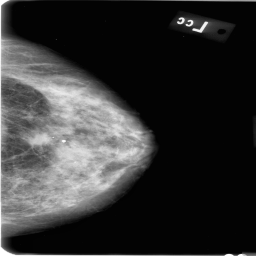

In [4]:
# CELL 4 — Preprocessing function and transforms
# FIX 3 & 4: Resize FIRST (256x256), then apply CLAHE on the small image.
#             NLM denoising is OFF by default (was causing ~7 h caching time).
#             Threshold ROI is OFF by default (was zeroing 99% of breast tissue).

def preprocess_mammogram(path):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        with Image.open(path) as im:
            gray = np.asarray(im.convert("L"))

    if gray.dtype != np.uint8:
        gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    # RESIZE FIRST — bilinear/AREA downsampling provides natural denoising
    gray = cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

    # Optional: background suppression (off by default)
    if USE_THRESHOLD_ROI:
        _, mask = cv2.threshold(gray, THRESHOLD_VALUE, 255, cv2.THRESH_BINARY)
        fraction = np.count_nonzero(mask) / mask.size
        if 0.005 <= fraction <= 0.95:
            gray = cv2.bitwise_and(gray, gray, mask=mask)

    # Optional: NLM denoising on small image (off by default)
    if USE_NLM_DENOISING:
        gray = cv2.fastNlMeansDenoising(
            gray, None, h=5, templateWindowSize=7, searchWindowSize=21
        )

    # Optional: median filter
    if USE_MEDIAN_FILTER:
        gray = cv2.medianBlur(gray, 3)

    # CLAHE: contrast-limited adaptive histogram equalization
    if USE_CLAHE:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = clahe.apply(gray)

    rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)
    return Image.fromarray(rgb)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Preview sample to verify preprocessing quality
sample_path = train_df.iloc[0]["resolved_path"]
t_start = time.time()
sample_img = preprocess_mammogram(sample_path)
elapsed = time.time() - t_start
print("Sample image path:", sample_path)
print(f"Processed size: {sample_img.size}  |  Time: {elapsed:.3f}s")
arr = np.array(sample_img)[:, :, 0]
print(f"Pixel stats — min:{arr.min()} max:{arr.max()} mean:{arr.mean():.1f}")
print(f"Pixels > 50: {(arr>50).mean()*100:.1f}%   Pixels > 100: {(arr>100).mean()*100:.1f}%")
display(sample_img)


In [5]:
# CELL 5 — Cache processed images (already resized; caching is fast now)
# If you change preprocessing settings, delete CACHE_ROOT and rebuild.

class CachedMammographyDataset(Dataset):
    def __init__(self, records, transform):
        self.records   = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]
        with Image.open(row["cached_path"]) as im:
            image = im.convert("RGB")
        return self.transform(image), int(row["binary_label"])


def build_cache(df, split_name):
    split_dir = os.path.join(CACHE_ROOT, split_name)
    os.makedirs(split_dir, exist_ok=True)
    records = []
    t0 = time.time()
    skipped = 0

    for idx, (_, row) in enumerate(df.iterrows()):
        cache_path = os.path.join(split_dir, f"{idx:05d}.png")
        if os.path.isfile(cache_path):
            skipped += 1
        else:
            img = preprocess_mammogram(row["resolved_path"])
            img.save(cache_path, optimize=False)

        records.append({
            "cached_path":  cache_path,
            "binary_label": int(row["binary_label"]),
        })

        if (idx + 1) % 200 == 0 or idx + 1 == len(df):
            elapsed = time.time() - t0
            rate = (idx + 1 - skipped) / max(elapsed, 1e-6)
            print(
                f"{split_name}: {idx+1}/{len(df)} "
                f"({skipped} already cached) | {rate:.1f} img/s",
                flush=True,
            )

    print(f"{split_name} cache done in {(time.time()-t0)/60:.1f} min")
    return records


train_records = build_cache(train_df, "train")
val_records   = build_cache(val_df,   "validation")
test_records  = build_cache(test_df,  "test")

pin_memory = device.type == "cuda"
train_ds = CachedMammographyDataset(train_records, train_transform)
val_ds   = CachedMammographyDataset(val_records,   eval_transform)
test_ds  = CachedMammographyDataset(test_records,  eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)
test_loader = DataLoader(
    test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory,
    persistent_workers=(NUM_WORKERS > 0),
)

print("\nDatasets ready.")
print(f"Train batches: {len(train_loader)}")
print(f"Val   batches: {len(val_loader)}")
print(f"Test  batches: {len(test_loader)}")

t0 = time.time()
xb, yb = next(iter(train_loader))
print(f"Cached batch loaded in {time.time()-t0:.2f}s")
print(f"Batch shape: {tuple(xb.shape)} | labels: {yb.tolist()}")


train: 200/2481 (0 already cached) | 2.4 img/s
train: 400/2481 (0 already cached) | 2.5 img/s
train: 600/2481 (0 already cached) | 2.5 img/s
train: 800/2481 (0 already cached) | 2.5 img/s
train: 1000/2481 (0 already cached) | 2.5 img/s
train: 1200/2481 (0 already cached) | 2.6 img/s
train: 1400/2481 (0 already cached) | 2.6 img/s
train: 1600/2481 (0 already cached) | 2.6 img/s
train: 1800/2481 (0 already cached) | 2.6 img/s
train: 2000/2481 (0 already cached) | 2.7 img/s
train: 2200/2481 (0 already cached) | 2.7 img/s
train: 2400/2481 (0 already cached) | 2.7 img/s
train: 2481/2481 (0 already cached) | 2.7 img/s
train cache done in 15.4 min
validation: 200/302 (0 already cached) | 2.7 img/s
validation: 302/302 (0 already cached) | 2.7 img/s
validation cache done in 1.9 min
test: 200/303 (0 already cached) | 2.9 img/s
test: 303/303 (0 already cached) | 2.9 img/s
test cache done in 1.8 min

Datasets ready.
Train batches: 1241
Val   batches: 151
Test  batches: 152
Cached batch loaded in 0

In [6]:
# CELL 6 — Build hybrid Swin-T + ResNet-50 + EfficientNet model
# FIX 5: EFFNET_VARIANT selects B2 (default, 9M params) or B7 (heavy, 66M params).
# Feature dims: Swin-T=768, ResNet-50=2048, B2=1408, B7=2560

EFFNET_CONFIG = {
    "b2": (efficientnet_b2, EfficientNet_B2_Weights.IMAGENET1K_V1, 1408),
    "b7": (efficientnet_b7, EfficientNet_B7_Weights.IMAGENET1K_V1, 2560),
}
if EFFNET_VARIANT not in EFFNET_CONFIG:
    raise ValueError(f"EFFNET_VARIANT must be 'b2' or 'b7', got '{EFFNET_VARIANT}'")

effnet_cls, effnet_weights_cls, effnet_dim = EFFNET_CONFIG[EFFNET_VARIANT]
fusion_dim = 768 + 2048 + effnet_dim


class HybridSwinCNN(nn.Module):
    # Swin-T + ResNet-50 + EfficientNet fusion classifier.
    # Fusion: Dropout(0.3) -> Linear(fusion_dim, 2)
    def __init__(self, pretrained=True):
        super().__init__()
        sw_w = Swin_T_Weights.IMAGENET1K_V1   if pretrained else None
        rn_w = ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
        ef_w = effnet_weights_cls             if pretrained else None

        self.swin = swin_t(weights=sw_w)
        self.swin.head = nn.Identity()

        self.resnet = resnet50(weights=rn_w)
        self.resnet.fc = nn.Identity()

        self.efficientnet = effnet_cls(weights=ef_w)
        self.efficientnet.classifier = nn.Identity()

        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(fusion_dim, 2)

    def forward(self, x):
        fs = self.swin(x)
        fr = self.resnet(x)
        fe = self.efficientnet(x)
        feat = torch.cat([fs, fr, fe], dim=1)
        return self.classifier(self.dropout(feat))


print(f"Loading ImageNet-pretrained hybrid model (EfficientNet-{EFFNET_VARIANT.upper()})...")
model = HybridSwinCNN(pretrained=True).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")
print(f"Fusion dimension : {fusion_dim}")
if torch.cuda.is_available():
    print("GPU allocated after model load:",
          round(torch.cuda.memory_allocated()/1024**3, 2), "GiB")

criterion = nn.CrossEntropyLoss()
scaler    = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))


Loading ImageNet-pretrained hybrid model (EfficientNet-B2)...
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 205MB/s]


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 257MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 216MB/s]


Total parameters: 58,736,830
Fusion dimension : 4224
GPU allocated after model load: 0.23 GiB


In [7]:
# CELL 7 — run_epoch helper + smoke test

def run_epoch(model, loader, optimizer=None, log_first_batch=False):
    training = optimizer is not None
    model.train(training)
    total_loss, total_count = 0.0, 0
    y_true, y_pred, y_prob = [], [], []

    for batch_idx, (xb, yb) in enumerate(loader):
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        if training and batch_idx == 0 and log_first_batch:
            print(
                f"First batch | shape={tuple(xb.shape)} | "
                f"device={xb.device} | model={next(model.parameters()).device}"
            )
            if torch.cuda.is_available():
                print("GPU allocated:",
                      round(torch.cuda.memory_allocated()/1024**3, 2), "GiB")

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(
                device_type=device.type, dtype=torch.float16,
                enabled=(device.type == "cuda"),
            ):
                logits = model(xb)
                loss   = criterion(logits, yb)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], 1.0
                )
                scaler.step(optimizer)
                scaler.update()

        n = yb.size(0)
        total_loss  += loss.item() * n
        total_count += n

        probs = torch.softmax(logits.detach(), dim=1)[:, 1]
        preds = (probs >= 0.5).long()
        y_true.extend(yb.detach().cpu().tolist())
        y_pred.extend(preds.cpu().tolist())
        y_prob.extend(probs.cpu().tolist())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "loss":        total_loss / max(total_count, 1),
        "accuracy":    accuracy_score(y_true, y_pred),
        "f1":          f1_score(y_true, y_pred, zero_division=0),
        "auc":         roc_auc_score(y_true, y_prob),
        "precision":   precision_score(y_true, y_pred, zero_division=0),
        "sensitivity": tp / (tp + fn) if tp + fn else 0.0,
        "specificity": tn / (tn + fp) if tn + fp else 0.0,
    }


# Smoke test: one forward pass
xb, yb = next(iter(val_loader))
model.eval()
with torch.no_grad(), torch.autocast(
    device_type=device.type, dtype=torch.float16,
    enabled=(device.type == "cuda"),
):
    out = model(xb.to(device))
print("Smoke test forward pass — output shape:", tuple(out.shape))


Smoke test forward pass — output shape: (2, 2)


In [8]:
# CELL 8 — Train head, then fine-tune all backbones
checkpoint_path = os.path.join(OUT_DIR, "hybrid_best_accuracy.pth")
history_path    = os.path.join(OUT_DIR, "hybrid_history.csv")

history      = []
best_val_acc  = -float("inf")
best_val_loss = float("inf")
best_val_auc  = float("nan")
best_state    = None
best_epoch    = None
bad_epochs    = 0

# Phase 1: freeze backbones, train fusion head only
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

head_opt = torch.optim.SGD(
    model.classifier.parameters(),
    lr=1e-4, momentum=0.9, nesterov=True, weight_decay=1e-4,
)

print("=" * 65)
print("PHASE 1: fusion head training")
for epoch in range(HEAD_EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, train_loader, head_opt, log_first_batch=(epoch == 0))
    va = run_epoch(model, val_loader)
    history.append({
        "phase": "head", "epoch": epoch + 1,
        **{f"train_{k}": v for k, v in tr.items()},
        **{f"val_{k}":   v for k, v in va.items()},
        "seconds": time.time() - t0,
    })
    print(
        f"Head {epoch+1}/{HEAD_EPOCHS} | "
        f"train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
        f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} "
        f"F1 {va['f1']:.4f} AUC {va['auc']:.4f} | "
        f"time {(time.time()-t0)/60:.1f} min",
        flush=True,
    )

# Phase 2: all parameters trainable, differential LRs
for p in model.parameters():
    p.requires_grad = True

backbone_params, head_params = [], []
for name, p in model.named_parameters():
    (head_params if name.startswith("classifier.") else backbone_params).append(p)

optimizer = torch.optim.SGD(
    [
        {"params": backbone_params, "lr": 1e-5},
        {"params": head_params,     "lr": 1e-4},
    ],
    momentum=0.9, nesterov=True, weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=FINETUNE_EPOCHS
)

print("\nPHASE 2: hybrid fine-tuning")
for epoch in range(FINETUNE_EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, train_loader, optimizer, log_first_batch=(epoch == 0))
    va = run_epoch(model, val_loader)
    scheduler.step()

    history.append({
        "phase": "finetune", "epoch": epoch + 1,
        **{f"train_{k}": v for k, v in tr.items()},
        **{f"val_{k}":   v for k, v in va.items()},
        "seconds": time.time() - t0,
    })

    print(
        f"Fine-tune {epoch+1}/{FINETUNE_EPOCHS} | "
        f"train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
        f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} "
        f"F1 {va['f1']:.4f} AUC {va['auc']:.4f} "
        f"Sens {va['sensitivity']:.4f} Spec {va['specificity']:.4f} | "
        f"time {(time.time()-t0)/60:.1f} min",
        flush=True,
    )

    improved = va["accuracy"] > best_val_acc
    if best_state is not None and np.isclose(va["accuracy"], best_val_acc):
        improved = va["loss"] < best_val_loss

    if improved:
        best_val_acc  = va["accuracy"]
        best_val_loss = va["loss"]
        best_val_auc  = va["auc"]
        best_epoch    = epoch + 1
        best_state    = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict":  best_state,
            "architecture":      f"HybridSwinT_ResNet50_EfficientNet{EFFNET_VARIANT.upper()}",
            "class_mapping":     {"benign": 0, "malignant": 1},
            "image_size":        IMG_SIZE,
            "effnet_variant":    EFFNET_VARIANT,
            "use_threshold_roi": USE_THRESHOLD_ROI,
            "threshold_value":   THRESHOLD_VALUE,
            "use_nlm":           USE_NLM_DENOISING,
            "use_median":        USE_MEDIAN_FILTER,
            "use_clahe":         USE_CLAHE,
            "best_epoch":        best_epoch,
            "best_val_accuracy": best_val_acc,
            "best_val_loss":     best_val_loss,
            "val_auc":           best_val_auc,
        }, checkpoint_path)
        bad_epochs = 0
        print("  Saved best checkpoint.", flush=True)
    else:
        bad_epochs += 1
        print(f"  No improvement ({bad_epochs}/{PATIENCE}).", flush=True)
        if bad_epochs >= PATIENCE:
            print("Early stopping.", flush=True)
            break

    pd.DataFrame(history).to_csv(history_path, index=False)

if best_state is None:
    raise RuntimeError("No checkpoint was saved during fine-tuning.")

model.load_state_dict(best_state)
pd.DataFrame(history).to_csv(history_path, index=False)
print(f"\nBest val accuracy : {best_val_acc:.4f}")
print(f"Best val AUC      : {best_val_auc:.4f}")
print(f"Selected epoch    : {best_epoch}")
print(f"Checkpoint saved  : {checkpoint_path}")


PHASE 1: fusion head training
First batch | shape=(2, 3, 256, 256) | device=cuda:0 | model=cuda:0
GPU allocated: 0.23 GiB
Head 1/2 | train loss 0.6911 acc 0.5429 | val loss 0.6740 acc 0.5894 F1 0.2250 AUC 0.5591 | time 1.3 min
Head 2/2 | train loss 0.6757 acc 0.5683 | val loss 0.6725 acc 0.5894 F1 0.3111 AUC 0.5588 | time 1.2 min

PHASE 2: hybrid fine-tuning
First batch | shape=(2, 3, 256, 256) | device=cuda:0 | model=cuda:0
GPU allocated: 0.24 GiB
Fine-tune 1/12 | train loss 0.6679 acc 0.5732 | val loss 0.6715 acc 0.5927 F1 0.1745 AUC 0.5618 Sens 0.1040 Spec 0.9379 | time 3.4 min
  Saved best checkpoint.
Fine-tune 2/12 | train loss 0.6681 acc 0.5732 | val loss 0.6736 acc 0.5960 F1 0.2375 AUC 0.5572 Sens 0.1520 Spec 0.9096 | time 3.2 min
  Saved best checkpoint.
Fine-tune 3/12 | train loss 0.6663 acc 0.5792 | val loss 0.6751 acc 0.5828 F1 0.1923 AUC 0.5566 Sens 0.1200 Spec 0.9096 | time 3.2 min
  No improvement (1/4).
Fine-tune 4/12 | train loss 0.6656 acc 0.5736 | val loss 0.6721 acc 

In [9]:
# CELL 9 — Final held-out test evaluation (run once after model selection)
# Do NOT tune hyperparameters or preprocessing based on these numbers.
ckpt = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

test_metrics = run_epoch(model, test_loader)
print("=" * 65)
print("FINAL TEST METRICS — threshold 0.50")
for key, val in test_metrics.items():
    print(f"  {key:15s}: {val:.4f}")

test_true, test_pred, test_probs = [], [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device, non_blocking=True)
        with torch.autocast(
            device_type=device.type, dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            logits = model(xb)
        prob = torch.softmax(logits, dim=1)[:, 1]
        pred = (prob >= 0.5).long()
        test_true.extend(yb.numpy().tolist())
        test_pred.extend(pred.cpu().tolist())
        test_probs.extend(prob.cpu().tolist())

print("\nClassification report (0=benign, 1=malignant)")
print(classification_report(
    test_true, test_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0,
))
print("Confusion matrix [true rows x predicted columns]:")
print(confusion_matrix(test_true, test_pred, labels=[0, 1]))
print("\nCheckpoint:", checkpoint_path)
print("History   :", history_path)


FINAL TEST METRICS — threshold 0.50
  loss           : 0.6534
  accuracy       : 0.6139
  f1             : 0.2252
  auc            : 0.6274
  precision      : 0.6071
  sensitivity    : 0.1382
  specificity    : 0.9389

Classification report (0=benign, 1=malignant)
              precision    recall  f1-score   support

      Benign       0.61      0.94      0.74       180
   Malignant       0.61      0.14      0.23       123

    accuracy                           0.61       303
   macro avg       0.61      0.54      0.48       303
weighted avg       0.61      0.61      0.53       303

Confusion matrix [true rows x predicted columns]:
[[169  11]
 [106  17]]

Checkpoint: /kaggle/working/cbis_ddsm_preparation/hybrid_best_accuracy.pth
History   : /kaggle/working/cbis_ddsm_preparation/hybrid_history.csv


## Tips if the notebook is slow or runs out of memory

| Symptom | Fix |
|---------|-----|
| CUDA OOM | Set `BATCH_SIZE = 1`, `EVAL_BATCH_SIZE = 1`, restart runtime, rerun from Cell 1. Or use `EFFNET_VARIANT = "b2"` (default). |
| Cache images look bad | Set `USE_THRESHOLD_ROI = False`, delete `/kaggle/working/cbis_preprocessed_cache`, rerun from Cell 5. |
| Slow first run | Normal — building cache for ~2700 images at ~0.01 s/image. Subsequent runs reuse PNGs. |
| Session restarted | Rerun all cells in order. Split CSVs are recreated in Cell 2 if missing. |
| Want heavier model | Set `EFFNET_VARIANT = "b7"` and `BATCH_SIZE = 1` — only if you have >= 24 GB VRAM. |
